In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay

import os

os.chdir("C:/Users/SEBASTIAN/Documents/Cursos/curso_ciencia_de_datos/30_days_of_python/Regresion_logistica_con_sklearn/")

In [2]:
df= pd.read_csv("Dry_Bean.csv")
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df["Class"].unique()

array(['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
      dtype=object)

In [4]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [5]:
#Eliminar duplicados
df.drop_duplicates(inplace= True)

In [6]:
#Verificar si hay datos nulos
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

(array([   0.,  500., 1000., 1500., 2000., 2500., 3000., 3500., 4000.]),
 [Text(0.0, 0, '0'),
  Text(500.0, 0, '500'),
  Text(1000.0, 0, '1000'),
  Text(1500.0, 0, '1500'),
  Text(2000.0, 0, '2000'),
  Text(2500.0, 0, '2500'),
  Text(3000.0, 0, '3000'),
  Text(3500.0, 0, '3500'),
  Text(4000.0, 0, '4000')])

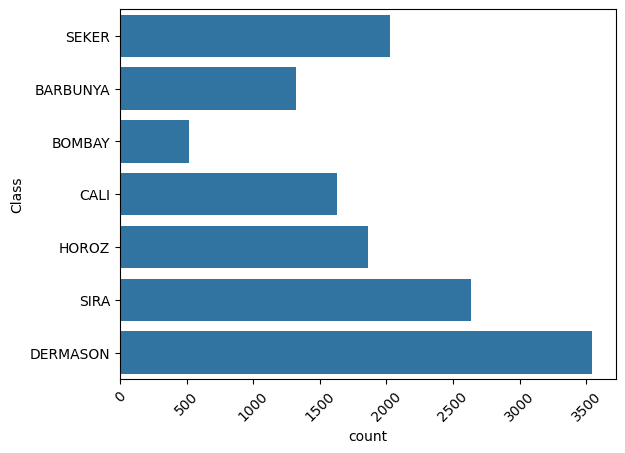

In [7]:
#BALANCEAR LOS DATOS

sns.countplot(df["Class"])
plt.xticks(rotation= 45)

#Hay 2 formas de balancear los datos
# Undersampling: Reducir todos los datos al de menor tamaño. EJ: La clase A = 2000, B= 2500, C= 500. Entonces se reducen todos los datasets a 500.
#El problema es que se estan perdiendo muchos datos.
# Oversampling: Crear datos con la misma sd, varianza y otras caracteristicas para que todas las clases tengan el numero de datos de la mayor clase.
#El problema es que se estan creando datos que no necesariamente son ciertos.

#Para este ejemplo, dado que la clase minima tiene 500 datos (podrian ser suficientes), se hara undersampling.

(array([  0., 100., 200., 300., 400., 500., 600.]),
 [Text(0.0, 0, '0'),
  Text(100.0, 0, '100'),
  Text(200.0, 0, '200'),
  Text(300.0, 0, '300'),
  Text(400.0, 0, '400'),
  Text(500.0, 0, '500'),
  Text(600.0, 0, '600')])

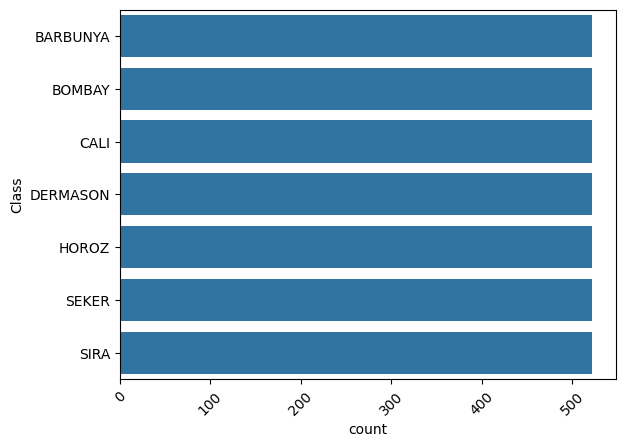

In [8]:
#Undersampling
from imblearn.under_sampling import RandomUnderSampler

under_sample = RandomUnderSampler(random_state= 42)

#Definir X, y 
X= df.drop("Class", axis=1)
y= df.Class 

X_over, y_over= under_sample.fit_resample(X,y)
sns.countplot(y_over)
plt.xticks(rotation= 45)

In [9]:
print(df.shape)
print(X_over.shape) #Hay una reduccion importante de datos, pero aun siguen habiendo suficientes para los analisis

(13543, 17)
(3654, 16)


In [10]:
#Convertir las clases a numeros
list(np.unique(y_over)) #Obtener la lista de las clases unicas
y_over.replace(['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA'], [1,2,3,4,5,6,7], inplace= True)

C:\Users\SEBASTIAN\AppData\Local\Temp\ipykernel_4816\1919242629.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_over.replace(['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA'], [1,2,3,4,5,6,7], inplace= True)


<Axes: >

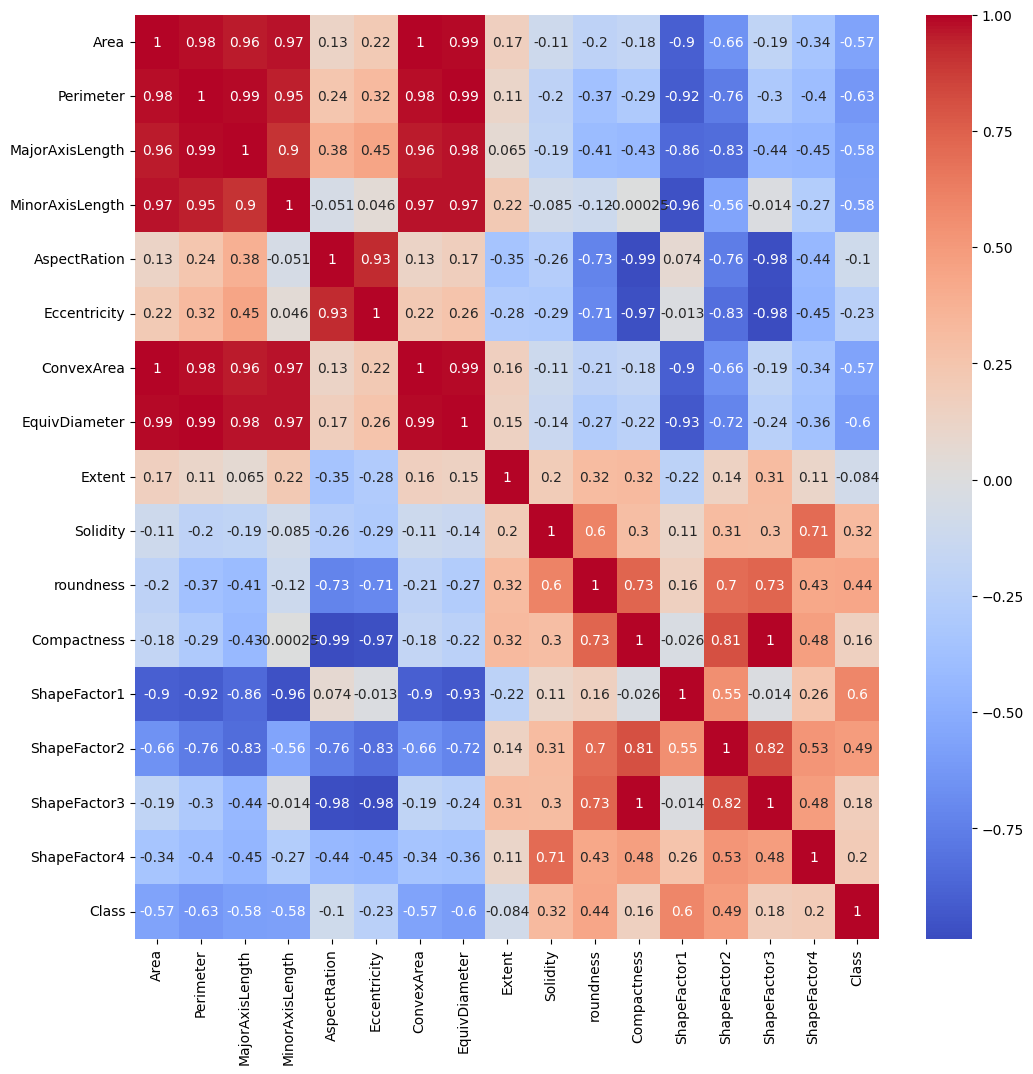

In [11]:
#Correlaciones
#df_dea= X_over
#df_dea["Class"] = y_over

new_data= pd.concat([X_over, y_over], axis= 1)

plt.figure(figsize= (12,12))
sns.heatmap(new_data.corr(), annot= True, cmap= "coolwarm")

In [12]:
#Eliminar las variables que tienen una correlacion muy alta porque pueden afectar el modelo

X_over.drop(["ConvexArea", "EquivDiameter"], axis= 1, inplace= True)

In [ ]:
sns.pairplot(new_data, hue= "Class")

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_over, y_over, test_size= 0.2, random_state= 42, shuffle= True) #shuffle es para distribuir bien las clases

st_x= StandardScaler()
X_train = st_x.fit_transform(X_train)
X_test = st_x.transform(X_test) #Solo transformar pero no entrenar para que no tome informacion del entrenamiento al test

In [ ]:
#Crear modelo y establecer parametros

def logistic_model(C_, solver_, multiclass_):
    logistic_regression_model= LogisticRegression(random_state= 42, solver= solver_, multi_class= multiclass_, n_jobs= -1, C= C_)
    return logistic_regression_model

model= logistic_model(1, "saga", "multinomial")
model.fit(X_train, y_train)

c:\Users\SEBASTIAN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(C=1, multi_class='multinomial', n_jobs=-1, random_state=42,
                   solver='saga')

In [ ]:
predictions= model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[119   0   5   0   1   0   3]
 [  0  98   0   0   0   0   0]
 [  5   0  97   0   0   0   1]
 [  0   0   0  90   0   5  10]
 [  0   0   4   1  91   0   0]
 [  3   0   0   0   0  84   4]
 [  0   0   1   6   6   0  97]]
0.9247606019151847


In [ ]:
#Crear el modelo con diferentes parametros
multiclass_list= ["ovr", "multinomial"]
solver_list= ["liblinear", "newton-cg","lbfgs", "sag", "saga"]
scores= []
params= []

for i in multiclass_list:
    for j in solver_list:
        try:
            model= logistic_model(1, j, i)
            model.fit(X_train, y_train)
            predictions= model.predict(X_test)
            params.append(i + " + " + j)
            accuracy= accuracy_score(y_test, predictions)
            scores.append(accuracy)
        except:
            None

([0, 1, 2, 3, 4, 5, 6, 7, 8],
 [Text(0, 0, 'ovr + liblinear'),
  Text(1, 0, 'ovr + newton-cg'),
  Text(2, 0, 'ovr + lbfgs'),
  Text(3, 0, 'ovr + sag'),
  Text(4, 0, 'ovr + saga'),
  Text(5, 0, 'multinomial + newton-cg'),
  Text(6, 0, 'multinomial + lbfgs'),
  Text(7, 0, 'multinomial + sag'),
  Text(8, 0, 'multinomial + saga')])

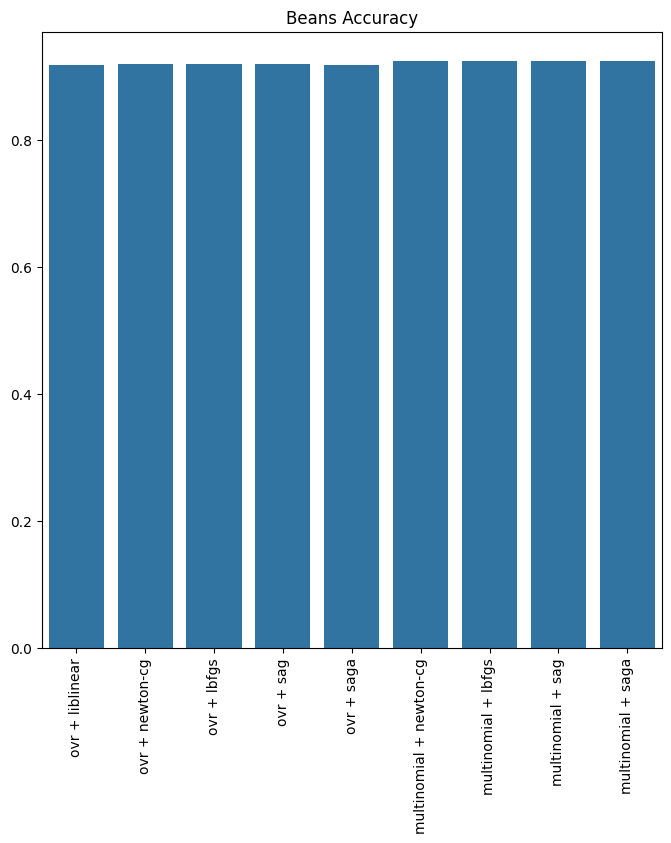

In [ ]:
fig= plt.figure(figsize= (8,8))
sns.barplot(x= params, y= scores).set_title("Beans Accuracy") 
plt.xticks(rotation= 90)

#Los resultados indican que la mejor combinacion es multinomial + newton-cg

In [ ]:
model= logistic_model(1, "newton-cg", "multinomial")
model.fit(X_train, y_train)
predictions= model.predict(X_test)
print(confusion_matrix(y_test, predictions))
print(accuracy_score(y_test, predictions))

[[119   0   5   0   1   0   3]
 [  0  98   0   0   0   0   0]
 [  5   0  97   0   0   0   1]
 [  0   0   0  90   0   5  10]
 [  0   0   4   1  91   0   0]
 [  3   0   0   0   0  84   4]
 [  0   0   1   6   6   0  97]]
0.9247606019151847


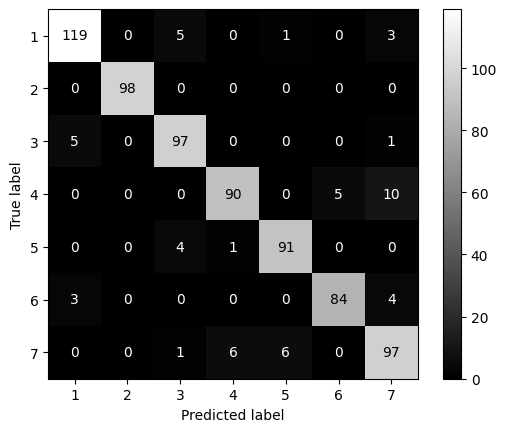

In [ ]:
cm= confusion_matrix(y_test, predictions, labels= model.classes_)
disp= ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= model.classes_)
disp.plot(cmap="gray")

In [ ]:
#OTRA FORMA DE ELEGIR LOS PARAMETROS
from sklearn.model_selection import GridSearchCV
import warnings

warnings.filterwarnings("ignore")

#Parametros grid

parameters= {
    "solver": ["liblinear", "newton-cg","lbfgs", "sag", "saga"],
    "multi_class": ["ovr", "multinomial"]
}

log_reg = LogisticRegression()

clf= GridSearchCV(
    log_reg, #modelo
    param_grid= parameters, #hiperparametros
    scoring= "accuracy", #metrica 
    cv= 10  
)

clf.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=LogisticRegression(),
             param_grid={'multi_class': ['ovr', 'multinomial'],
                         'solver': ['liblinear', 'newton-cg', 'lbfgs', 'sag',
                                    'saga']},
             scoring='accuracy')

In [ ]:
print("Mejores hiperparametros: ", clf.best_params_)
print("Mejor accuracy: ", clf.best_score_)

Mejores hiperparametros:  {'multi_class': 'multinomial', 'solver': 'lbfgs'}
Mejor accuracy:  0.9360173453644396


0.9247606019151847


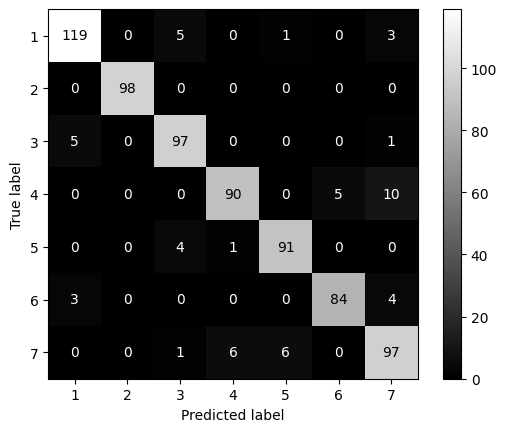

In [ ]:
predictions= clf.predict(X_test)
print(accuracy_score(y_test, predictions))

cm= confusion_matrix(y_test, predictions, labels= clf.classes_)
disp= ConfusionMatrixDisplay(confusion_matrix= cm, display_labels= clf.classes_)
disp.plot(cmap="gray")

In [ ]:
from sklearn.metrics import classification_report

target_names= y_test.unique()
results= classification_report(y_test, predictions, target_names= target_names)
print(results)